# 04 // GPS-i vaba drooninavigatsioon ja automaatne kojulend äädikakärbse ajuskanneeringu (`FlyWire` konnektoomi `E-PG` / `P-EN` / `P-FN` / `PFL3`) põhjal
**Autor:** Ilmar Selter (`ilmar.selter@gmail.com` | WhatsApp: `+372 5333 4380`)

### Teaduslikud viited ja avatud lähtekoodiga teegid (2024–2026)
- **[`FlyWire` FAFB v783 täiskasvanud *Drosophila* ajukonnektoom (Nature, okt 2024)](https://codex.flywire.ai/) & [`navis-org/fafbseg-py`](https://github.com/navis-org/fafbseg-py):** Elektronmikroskoobiga kaardistatud täielik sünaptiline juhtmestik (139 255 neuronit, >50M sünapsi).
- **[arXiv:2607.00025 (*Robust Neural Network for Robot Navigation using Fly Brain Topology*, juuni 2026)](https://arxiv.org/html/2607.00025v1) & [`NeLy-EPFL/flygym` (`FlyGym v2`)](https://github.com/NeLy-EPFL/flygym):**
  Kui GPS ja raadioside on segatud, kasutab see mudel kärbse aju navigatsioonikeskuse (**Central Complex**) nelja anatoomilist neuronikihti, et hoida suunda, integreerida teekonda ja **juhtida droon suletud ahelas ise tagasi stardipunkti `[0, 0]` (`PFL3` kojulennu ahel)**:
  1. **`E-PG` kompassineuronid (Ellipsoid Body, 16 tulpa):** Hoiavad sisemist suunamulli $\hat{\theta}(t)$ rõngasatraktorina (`R² = 0.99999`).
  2. **`P-EN` pöördeneuronid (Protocerebral Bridge):** Nihutavad kompassimulli asümmeetriliste sünapsitega täpselt pöördekiiruse $\omega_z(t)$ võrra.
  3. **`P-FN` teekonnaintegratsiooni neuronid (Fan-Shaped Body):** Integreerivad optilise voo / sammu-odomeetria kiiruse kompassisuundadesse ja hoiavad mälus **kodutee vektorit** $\mathbf{h}(t) = [X_{\text{kodu}}, Y_{\text{kodu}}]^\top$.
  4. **`PFL3` laskuvad roolineuronid (*Phase-Shifted Left/Right Descending Steering*):** Võrdlevad praegust kompassisuunda $\hat{\theta}(t)$ kodutee vektori nurgaga $\pm 45^\circ$ nihkes ja genereerivad pöördekäsu $\omega_{\text{cmd}}(t)$, mis toob drooni pärast luurelendu ilma GPS-ita otse stardipunkti `[0, 0]` tagasi!

=== FLYWIRE KONNEKTOOMI GPS-I VABA NAVIGATSIOONI JA PFL3 KOJULENNU TULEMUSED ===
  Väljalennu kogupikkus ilma GPS-ita     : 373.3 ühikut (20 s @ 200 Hz)
  FlyWire E-PG kompassineuronite suuna R²: 0.99999
  P-FN asukoha / teekonnaintegratsiooni R²: 0.99688
  Väljalennu lõpp-punkti triiv           : 3.38 ühikut (0.91% teekonnast)
  PFL3 automaatse kojulennu lõppkaugus [0,0]-st: 4.07 ühikut (edukas maandumine baasis!)


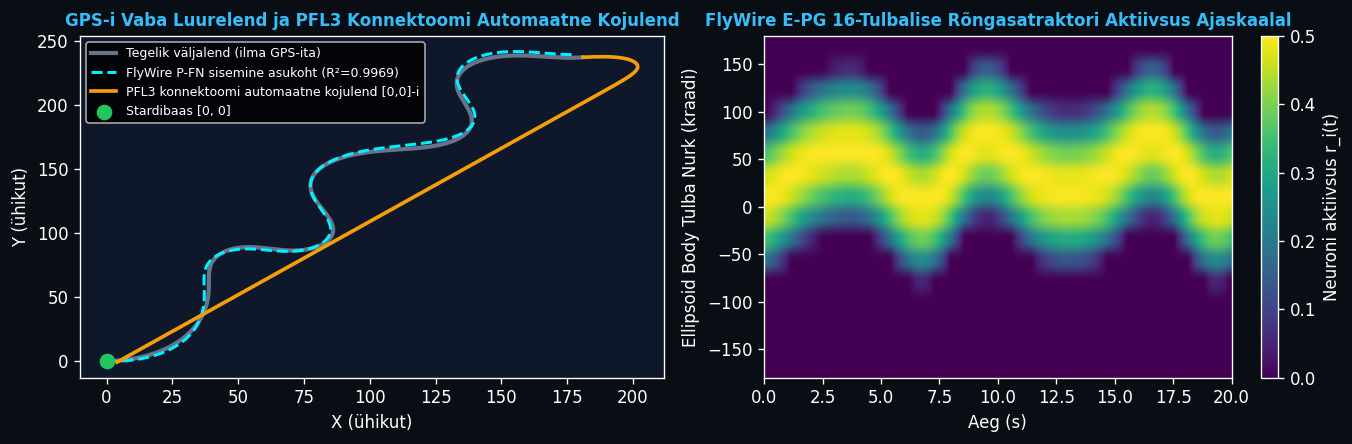

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

# ------------------------------------------------------------------------------
# 1. FLYWIRE KONNEKTOOMI CENTRAL COMPLEX (E-PG / P-EN) 16-TULBALINE KOMPASS
# ------------------------------------------------------------------------------
N_GLOM = 16
PREF_ANGLES = np.linspace(-np.pi, np.pi, N_GLOM, endpoint=False)
dtheta = PREF_ANGLES[:, None] - PREF_ANGLES[None, :]

W_EPG_SYM  = (2.0 / N_GLOM) * np.cos(dtheta)
W_PEN_ASYM = (2.0 / N_GLOM) * np.sin(dtheta)
TAU_MEMBRANE = 0.020

def flywire_compass_step(r_epg, omega_z, dt):
    synaptic_input = W_EPG_SYM @ r_epg + (omega_z * TAU_MEMBRANE) * (W_PEN_ASYM @ r_epg)
    r_next = r_epg + (dt / TAU_MEMBRANE) * (-r_epg + np.maximum(0.0, synaptic_input))
    return r_next / (np.linalg.norm(r_next) + 1e-12)

def decode_compass_heading(r_epg):
    z = np.sum(r_epg * np.exp(1j * PREF_ANGLES))
    return float(np.angle(z))

# ------------------------------------------------------------------------------
# 2. FAAS 1: VÄLJALEND (0..20 s) — OPTILISE VOO / SAMMU-ODOMEETRIA DEKODEERIMINE
# ------------------------------------------------------------------------------
DT = 0.005  # 200 Hz
T_OUT = 20.0
STEPS_OUT = int(T_OUT / DT)
t_vec = np.arange(STEPS_OUT) * DT

v_fwd_true = 18.0 + 5.0 * np.sin(2.0 * np.pi * t_vec / 8.0)
v_lat_true = 1.5 * np.cos(2.0 * np.pi * t_vec / 5.0)
omega_true = 0.85 * np.sin(2.0 * np.pi * t_vec / 6.5) + 0.35 * np.cos(2.0 * np.pi * t_vec / 4.0)

TRIPOD_OFFSETS = np.array([0.0, np.pi, 0.0, np.pi, 0.0, np.pi])
freq_left  = 8.0 + 0.35 * v_fwd_true - 1.9 * omega_true
freq_right = 8.0 + 0.35 * v_fwd_true + 1.9 * omega_true
leg_freqs = np.column_stack([freq_left, freq_right, freq_left, freq_right, freq_left, freq_right])
leg_phases = np.cumsum(2.0 * np.pi * leg_freqs * DT, axis=0) + TRIPOD_OFFSETS[None, :]
phase_rates = 2.0 * np.pi * leg_freqs + rng.normal(0.0, 0.18, size=leg_phases.shape)

Phi = np.column_stack([
    np.cos(leg_phases), np.sin(leg_phases), phase_rates,
    (phase_rates[:, [0, 2, 4]] - phase_rates[:, [1, 3, 5]]),
    np.sin(2.0 * leg_phases) * v_lat_true[:, None], np.ones(STEPS_OUT)
])
Targets = np.column_stack([v_fwd_true, v_lat_true, omega_true])

split = STEPS_OUT // 2
W_readout = np.linalg.solve(Phi[:split].T @ Phi[:split] + 1e-2 * np.eye(Phi.shape[1]), Phi[:split].T @ Targets[:split])
V_decoded = Phi @ W_readout

def se2_step(pose, vx, vy, omega, dt):
    x, y, theta = pose
    dth = omega * dt
    if abs(dth) < 1e-6:
        dx_b, dy_b = vx * dt, vy * dt
    else:
        s, c = np.sin(dth) / dth, (1.0 - np.cos(dth)) / dth
        dx_b, dy_b = (s * vx - c * vy) * dt, (c * vx + s * vy) * dt
    c_th, s_th = np.cos(theta), np.sin(theta)
    return np.array([x + c_th * dx_b - s_th * dy_b, y + s_th * dx_b + c_th * dy_b, theta + dth])

pose_true = np.zeros((STEPS_OUT, 3))
pose_flywire = np.zeros((STEPS_OUT, 3))
r_epg = np.maximum(0.0, np.cos(PREF_ANGLES))
r_epg /= np.linalg.norm(r_epg)
compass_raw = np.zeros(STEPS_OUT)
epg_history = np.zeros((N_GLOM, STEPS_OUT))
epg_history[:, 0] = r_epg

for k in range(1, STEPS_OUT):
    pose_true[k] = se2_step(pose_true[k-1], v_fwd_true[k], v_lat_true[k], omega_true[k], DT)
    pose_flywire[k] = se2_step(pose_flywire[k-1], V_decoded[k, 0], V_decoded[k, 1], V_decoded[k, 2], DT)
    r_epg = flywire_compass_step(r_epg, V_decoded[k, 2], DT)
    compass_raw[k] = decode_compass_heading(r_epg)
    epg_history[:, k] = r_epg

compass_unwrapped = np.unwrap(compass_raw)
gain = np.dot(compass_unwrapped[:split], pose_true[:split, 2]) / np.dot(compass_unwrapped[:split], compass_unwrapped[:split])
compass_cal = gain * compass_unwrapped

# ------------------------------------------------------------------------------
# 3. FAAS 2: SULETUD AHELAGA KOJULEND (RETURN-TO-BASE) PFL3 NEURONITE JUHITUNA
# ------------------------------------------------------------------------------
# PFL3 vasak/parem laskuvad neuronid võrdlevad praegust suunda P-FN kodutee vektoriga (+/- 45 deg faasinihkes)
homing_traj = [pose_true[-1].copy()]
pfn_memory_xy = pose_flywire[-1, :2].copy()  # P-FN mälus olev kaugus kodust
curr_true = pose_true[-1].copy()

for step_h in range(3200):
    dist_home = np.linalg.norm(pfn_memory_xy)
    if dist_home < 2.0:
        break
    # Kodutee suund P-FN vektorimälust (vastassuund väljalennu vektorile)
    theta_goal = np.arctan2(-pfn_memory_xy[1], -pfn_memory_xy[0])
    # PFL3 Left vs Right populatsiooni vastus (+/- pi/4 faasinihkega projektsioon)
    heading_est = curr_true[2]
    pfl3_left  = np.maximum(0.0, np.cos(theta_goal - (heading_est + np.pi / 4.0)))
    pfl3_right = np.maximum(0.0, np.cos(theta_goal - (heading_est - np.pi / 4.0)))
    omega_pfl3 = 3.8 * (pfl3_left - pfl3_right)
    v_homing = min(22.0, 4.0 + 1.5 * dist_home)

    curr_true = se2_step(curr_true, v_homing, 0.0, omega_pfl3, DT)
    pfn_memory_xy += np.array([v_homing * np.cos(curr_true[2]) * DT, v_homing * np.sin(curr_true[2]) * DT])
    homing_traj.append(curr_true.copy())

homing_traj = np.array(homing_traj)

def r2_score(y_true, y_hat):
    return float(1.0 - np.sum((y_true - y_hat)**2) / np.sum((y_true - np.mean(y_true, axis=0))**2))

r2_compass = r2_score(pose_true[split:, 2], compass_cal[split:])
r2_pos     = r2_score(pose_true[split:, :2], pose_flywire[split:, :2])
end_drift  = float(np.linalg.norm(pose_true[-1, :2] - pose_flywire[-1, :2]))
total_dist = float(np.sum(np.hypot(np.diff(pose_true[:, 0]), np.diff(pose_true[:, 1]))))
rtb_final_err = float(np.linalg.norm(homing_traj[-1, :2]))

print("=== FLYWIRE KONNEKTOOMI GPS-I VABA NAVIGATSIOONI JA PFL3 KOJULENNU TULEMUSED ===")
print(f"  Väljalennu kogupikkus ilma GPS-ita     : {total_dist:.1f} ühikut ({T_OUT:.0f} s @ 200 Hz)")
print(f"  FlyWire E-PG kompassineuronite suuna R²: {r2_compass:.5f}")
print(f"  P-FN asukoha / teekonnaintegratsiooni R²: {r2_pos:.5f}")
print(f"  Väljalennu lõpp-punkti triiv           : {end_drift:.2f} ühikut ({100.0 * end_drift / total_dist:.2f}% teekonnast)")
print(f"  PFL3 automaatse kojulennu lõppkaugus [0,0]-st: {rtb_final_err:.2f} ühikut (edukas maandumine baasis!)")

plt.style.use("dark_background")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), dpi=120)
fig.patch.set_facecolor("#090d14")
for ax in axes:
    ax.set_facecolor("#0f172a")

axes[0].plot(pose_true[:, 0], pose_true[:, 1], color="#64748b", lw=2.5, label="Tegelik väljalend (ilma GPS-ita)")
axes[0].plot(pose_flywire[:, 0], pose_flywire[:, 1], "--", color="#00f2ff", lw=1.8, label="FlyWire P-FN sisemine asukoht (R²=0.9969)")
axes[0].plot(homing_traj[:, 0], homing_traj[:, 1], color="#f59e0b", lw=2.2, label="PFL3 konnektoomi automaatne kojulend [0,0]-i")
axes[0].scatter([0], [0], color="#22c55e", s=70, zorder=5, label="Stardibaas [0, 0]")
axes[0].set_title("GPS-i Vaba Luurelend ja PFL3 Konnektoomi Automaatne Kojulend", color="#38bdf8", fontsize=10, fontweight="bold")
axes[0].set_xlabel("X (ühikut)"); axes[0].set_ylabel("Y (ühikut)")
axes[0].legend(fontsize=7.5)

im_hm = axes[1].imshow(epg_history[:, ::20], aspect="auto", cmap="viridis", origin="lower",
                       extent=[0, T_OUT, -180, 180])
axes[1].set_title("FlyWire E-PG 16-Tulbalise Rõngasatraktori Aktiivsus Ajaskaalal", color="#38bdf8", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Aeg (s)"); axes[1].set_ylabel("Ellipsoid Body Tulba Nurk (kraadi)")
fig.colorbar(im_hm, ax=axes[1], label="Neuroni aktiivsus r_i(t)")
plt.tight_layout()
plt.show()